<a href="https://colab.research.google.com/github/Abhi02-Sathikumar/CROP_YIELD_PREDICTION/blob/main/notebooks/Weather_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

file_path = "/content/weather.csv"

df = pd.read_csv(file_path)


In [2]:

# Clean column names
df.columns = df.columns.str.strip()

print("Original Shape:", df.shape)
print("\nOriginal Columns:")
print(df.columns.tolist())

Original Shape: (12029, 29)

Original Columns:
['city', 'state', 'latitude', 'longitude', 'date', 'year', 'month', 'day_of_year', 'decade', 'weather_code', 'temp_max_c', 'temp_min_c', 'temp_range_c', 'apparent_temp_max_c', 'apparent_temp_min_c', 'precipitation_mm', 'rain_mm', 'snowfall_cm', 'precipitation_hours', 'is_monsoon_season', 'heatwave_day_simple_flag', 'sunshine_duration_sec', 'daylight_duration_sec', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wind_direction_dominant_deg', 'solar_radiation_mj_m2', 'reference_evapotranspiration_mm', 'has_missing_values']


In [3]:

columns_to_remove = [
    "latitude",
    "longitude",
    "date",
    "month",
    "date_of_year",
    "day_of_year",
    "decade",
    "city"
]

# Remove only columns that actually exist
existing_columns = [
    col for col in columns_to_remove
    if col in df.columns
]

df = df.drop(columns=existing_columns)

print("\nRemoved Columns:")
print(existing_columns)


Removed Columns:
['latitude', 'longitude', 'date', 'month', 'day_of_year', 'decade', 'city']


In [4]:

if "state" not in df.columns:
    raise ValueError("State column not found!")

print("\nNumber of States:",
      df["state"].nunique())

print("\nStates:")
print(df["state"].unique())

# All columns except state
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumeric Columns:")
print(numeric_columns)

state_wise_df = df.groupby(
    "state",
    as_index=False
)[numeric_columns].mean()


state_wise_df[numeric_columns] = (
    state_wise_df[numeric_columns].round(2)
)



Number of States: 1

States:
['Tripura']

Numeric Columns:
['year', 'weather_code', 'temp_max_c', 'temp_min_c', 'temp_range_c', 'apparent_temp_max_c', 'apparent_temp_min_c', 'precipitation_mm', 'rain_mm', 'snowfall_cm', 'precipitation_hours', 'sunshine_duration_sec', 'daylight_duration_sec', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wind_direction_dominant_deg', 'solar_radiation_mj_m2', 'reference_evapotranspiration_mm']


In [5]:


print("\nFinal State-Wise Dataset:")
display(state_wise_df)

print("\nFinal Shape:",
      state_wise_df.shape)

print("\nMissing Values:")
print(state_wise_df.isnull().sum())

output_file = "/content/india_statewise_climate.csv"

state_wise_df.to_csv(
    output_file,
    index=False
)

print("\nSaved successfully!")
print(output_file)


Final State-Wise Dataset:


,state,year,weather_code,temp_max_c,temp_min_c,temp_range_c,apparent_temp_max_c,apparent_temp_min_c,precipitation_mm,rain_mm,snowfall_cm,precipitation_hours,sunshine_duration_sec,daylight_duration_sec,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,solar_radiation_mj_m2,reference_evapotranspiration_mm
0,Tripura,1955.97,37.0,29.74,20.77,8.97,33.43,23.28,5.82,5.82,0.0,6.97,32349.17,43754.82,12.92,28.46,169.91,16.18,3.52



Final Shape: (1, 19)

Missing Values:
state                              0
year                               0
weather_code                       0
temp_max_c                         0
temp_min_c                         0
temp_range_c                       0
apparent_temp_max_c                0
apparent_temp_min_c                0
precipitation_mm                   0
rain_mm                            0
snowfall_cm                        0
precipitation_hours                0
sunshine_duration_sec              0
daylight_duration_sec              0
wind_speed_max_kmh                 0
wind_gusts_max_kmh                 0
wind_direction_dominant_deg        0
solar_radiation_mj_m2              0
reference_evapotranspiration_mm    0
dtype: int64

Saved successfully!
/content/india_statewise_climate.csv


In [6]:
# ============================================================
# EDA - EXPLORATORY DATA ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------------------
# 1. BASIC INFORMATION
# ------------------------------------------------------------

print("========== DATASET SHAPE ==========")
print(state_wise_df.shape)

print("\n========== DATASET INFO ==========")
state_wise_df.info()


# ------------------------------------------------------------
# 2. FIRST 5 ROWS
# ------------------------------------------------------------

print("\n========== FIRST 5 ROWS ==========")
display(state_wise_df.head())



========== DATASET SHAPE ==========
(1, 19)

========== DATASET INFO ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   state                            1 non-null      object 
 1   year                             1 non-null      float64
 2   weather_code                     1 non-null      float64
 3   temp_max_c                       1 non-null      float64
 4   temp_min_c                       1 non-null      float64
 5   temp_range_c                     1 non-null      float64
 6   apparent_temp_max_c              1 non-null      float64
 7   apparent_temp_min_c              1 non-null      float64
 8   precipitation_mm                 1 non-null      float64
 9   rain_mm                          1 non-null      float64
 10  snowfall_cm                      1 non-null      float64
 11  precipit

,state,year,weather_code,temp_max_c,temp_min_c,temp_range_c,apparent_temp_max_c,apparent_temp_min_c,precipitation_mm,rain_mm,snowfall_cm,precipitation_hours,sunshine_duration_sec,daylight_duration_sec,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,solar_radiation_mj_m2,reference_evapotranspiration_mm
0,Tripura,1955.97,37.0,29.74,20.77,8.97,33.43,23.28,5.82,5.82,0.0,6.97,32349.17,43754.82,12.92,28.46,169.91,16.18,3.52



========== LAST 5 ROWS ==========


,state,year,weather_code,temp_max_c,temp_min_c,temp_range_c,apparent_temp_max_c,apparent_temp_min_c,precipitation_mm,rain_mm,snowfall_cm,precipitation_hours,sunshine_duration_sec,daylight_duration_sec,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,solar_radiation_mj_m2,reference_evapotranspiration_mm
0,Tripura,1955.97,37.0,29.74,20.77,8.97,33.43,23.28,5.82,5.82,0.0,6.97,32349.17,43754.82,12.92,28.46,169.91,16.18,3.52



========== STATISTICAL SUMMARY ==========


,year,weather_code,temp_max_c,temp_min_c,temp_range_c,apparent_temp_max_c,apparent_temp_min_c,precipitation_mm,rain_mm,snowfall_cm,precipitation_hours,sunshine_duration_sec,daylight_duration_sec,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,solar_radiation_mj_m2,reference_evapotranspiration_mm
count,1.00,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
mean,1955.97,37.0,29.74,20.77,8.97,33.43,23.28,5.82,5.82,0.0,6.97,32349.17,43754.82,12.92,28.46,169.91,16.18,3.52
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1955.97,37.0,29.74,20.77,8.97,33.43,23.28,5.82,5.82,0.0,6.97,32349.17,43754.82,12.92,28.46,169.91,16.18,3.52
25%,1955.97,37.0,29.74,20.77,8.97,33.43,23.28,5.82,5.82,0.0,6.97,32349.17,43754.82,12.92,28.46,169.91,16.18,3.52
50%,1955.97,37.0,29.74,20.77,8.97,33.43,23.28,5.82,5.82,0.0,6.97,32349.17,43754.82,12.92,28.46,169.91,16.18,3.52
75%,1955.97,37.0,29.74,20.77,8.97,33.43,23.28,5.82,5.82,0.0,6.97,32349.17,43754.82,12.92,28.46,169.91,16.18,3.52
max,1955.97,37.0,29.74,20.77,8.97,33.43,23.28,5.82,5.82,0.0,6.97,32349.17,43754.82,12.92,28.46,169.91,16.18,3.52



========== NUMBER OF STATES ==========
Total States: 1

========== STATES ==========
['Tripura']

========== MISSING VALUES ==========


,Missing Values,Percentage
state,0,0.0
year,0,0.0
weather_code,0,0.0
temp_max_c,0,0.0
temp_min_c,0,0.0
temp_range_c,0,0.0
apparent_temp_max_c,0,0.0
apparent_temp_min_c,0,0.0
precipitation_mm,0,0.0
rain_mm,0,0.0



========== DUPLICATE ROWS ==========
Number of duplicate rows: 0

========== DATA TYPES ==========


,Column,Data Type
state,state,object
year,year,float64
weather_code,weather_code,float64
temp_max_c,temp_max_c,float64
temp_min_c,temp_min_c,float64
temp_range_c,temp_range_c,float64
apparent_temp_max_c,apparent_temp_max_c,float64
apparent_temp_min_c,apparent_temp_min_c,float64
precipitation_mm,precipitation_mm,float64
rain_mm,rain_mm,float64



========== UNIQUE VALUES ==========
state: 1 unique values
year: 1 unique values
weather_code: 1 unique values
temp_max_c: 1 unique values
temp_min_c: 1 unique values
temp_range_c: 1 unique values
apparent_temp_max_c: 1 unique values
apparent_temp_min_c: 1 unique values
precipitation_mm: 1 unique values
rain_mm: 1 unique values
snowfall_cm: 1 unique values
precipitation_hours: 1 unique values
sunshine_duration_sec: 1 unique values
daylight_duration_sec: 1 unique values
wind_speed_max_kmh: 1 unique values
wind_gusts_max_kmh: 1 unique values
wind_direction_dominant_deg: 1 unique values
solar_radiation_mj_m2: 1 unique values
reference_evapotranspiration_mm: 1 unique values

========== NUMERIC COLUMNS ==========
['year', 'weather_code', 'temp_max_c', 'temp_min_c', 'temp_range_c', 'apparent_temp_max_c', 'apparent_temp_min_c', 'precipitation_mm', 'rain_mm', 'snowfall_cm', 'precipitation_hours', 'sunshine_duration_sec', 'daylight_duration_sec', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wi

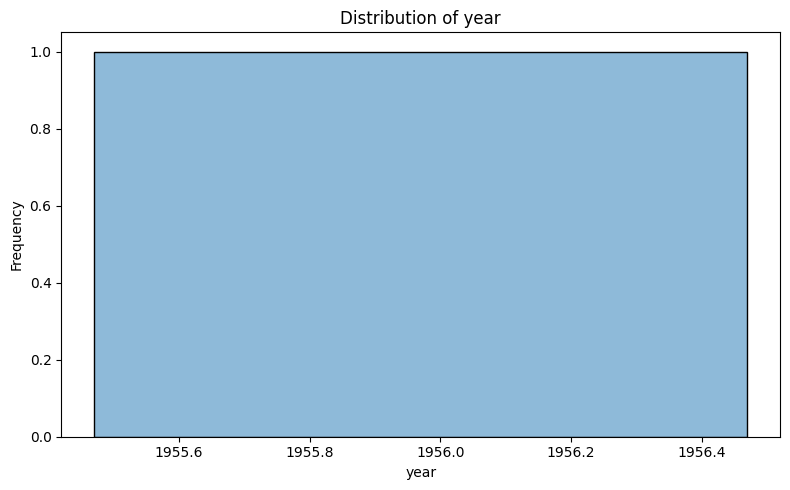

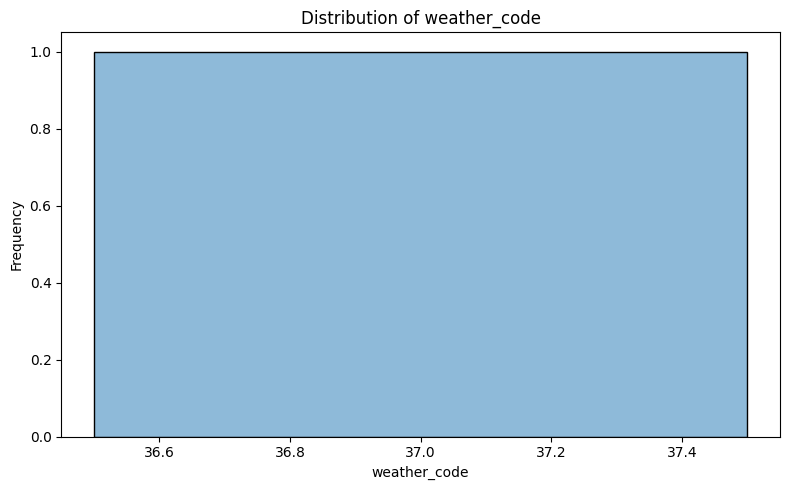

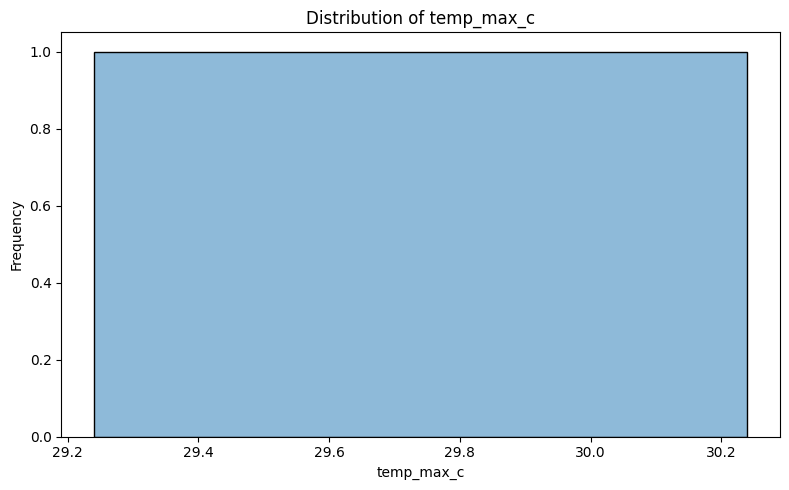

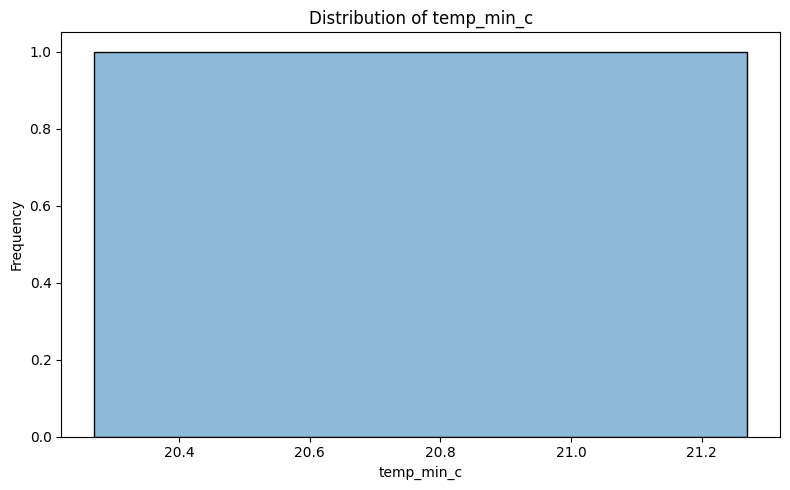

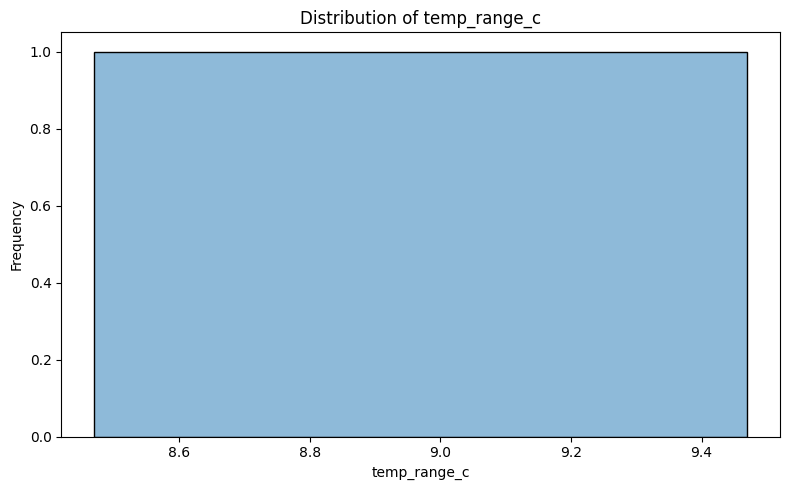

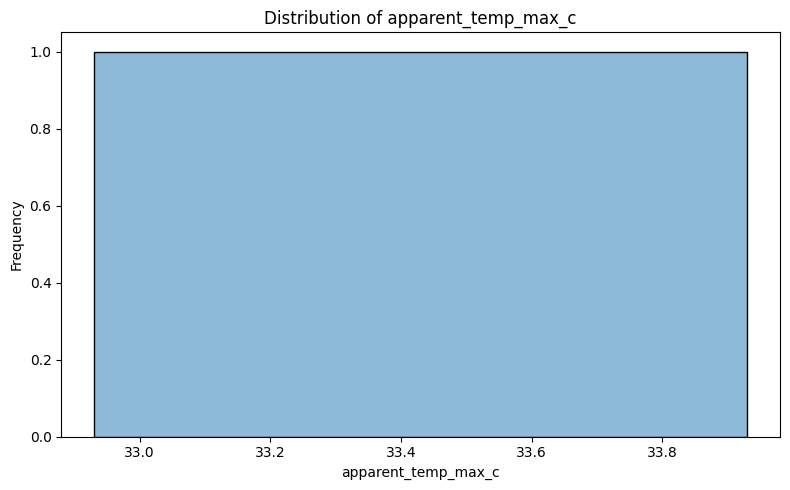

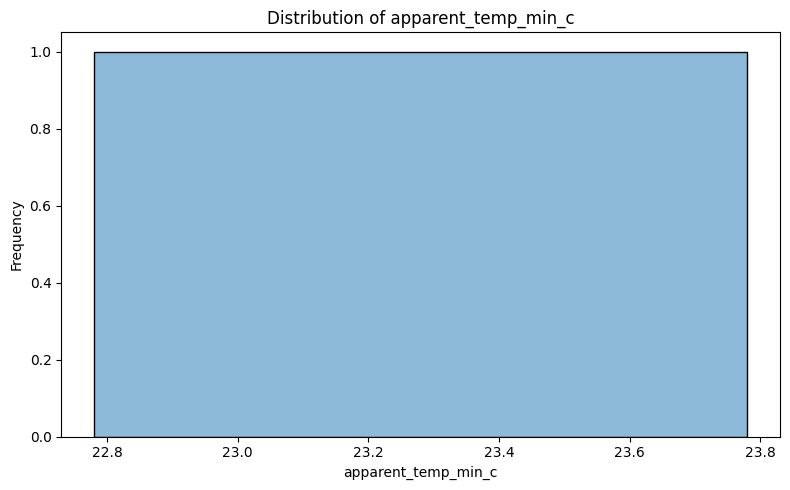

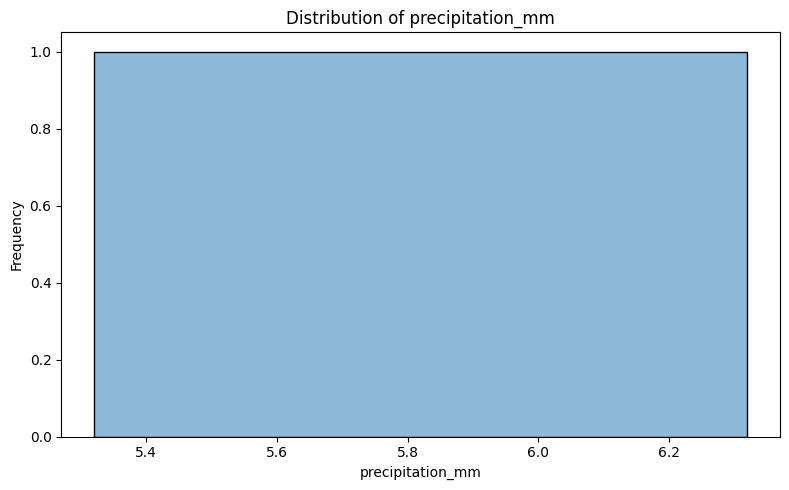

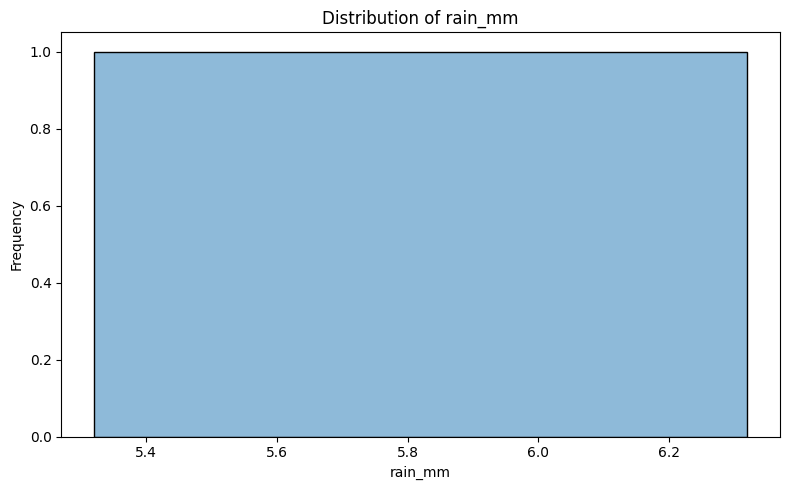

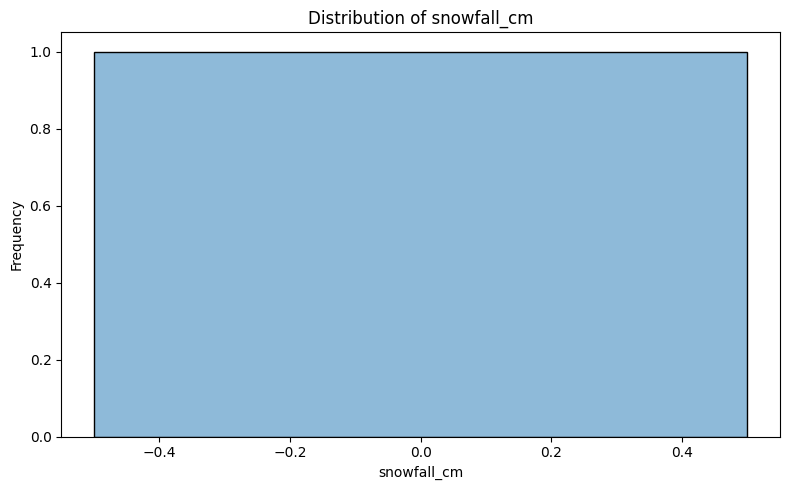

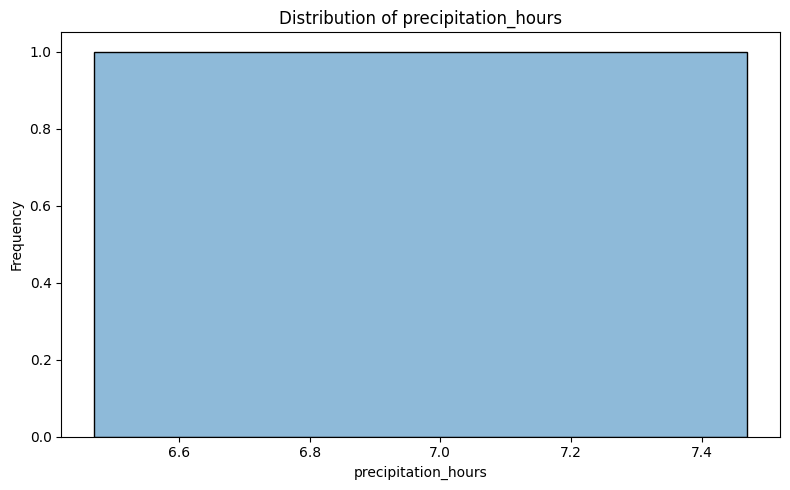

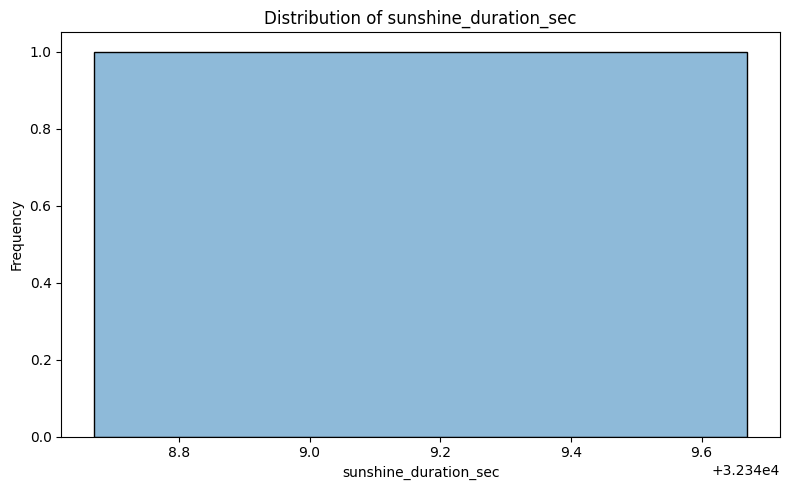

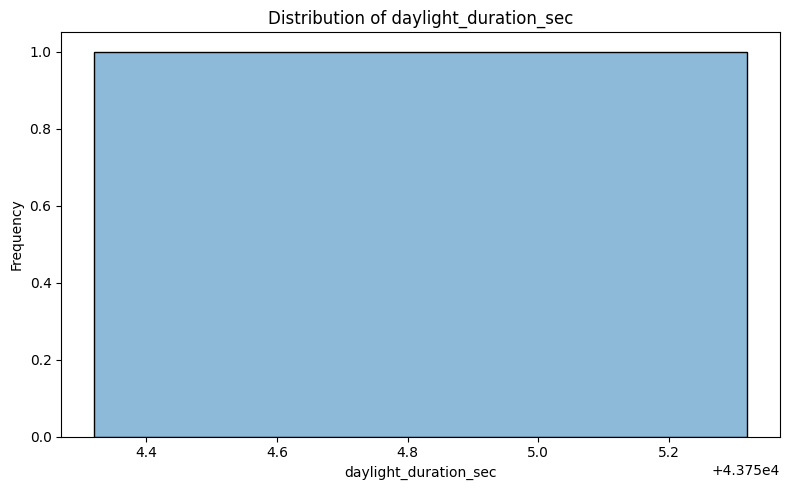

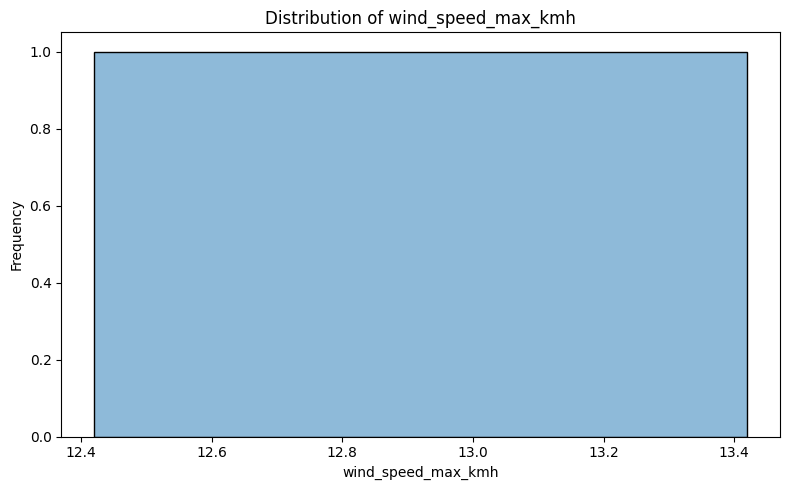

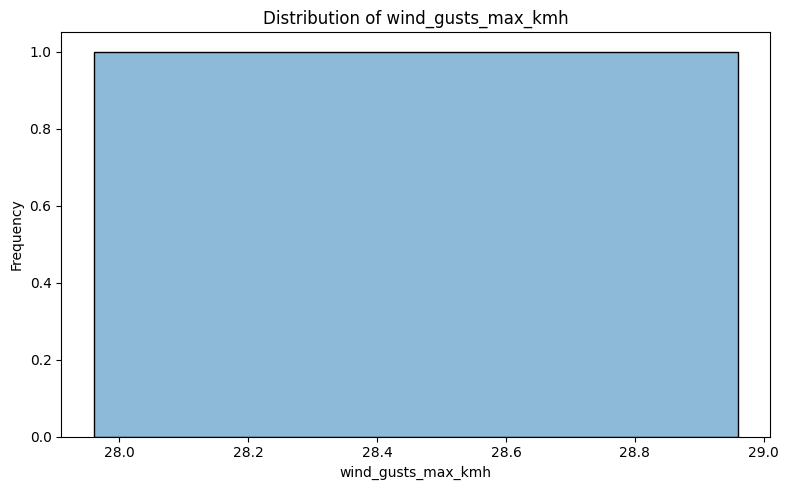

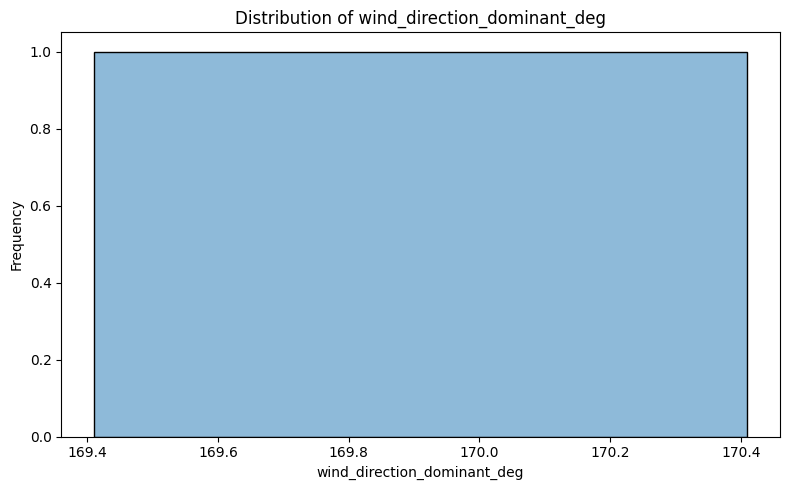

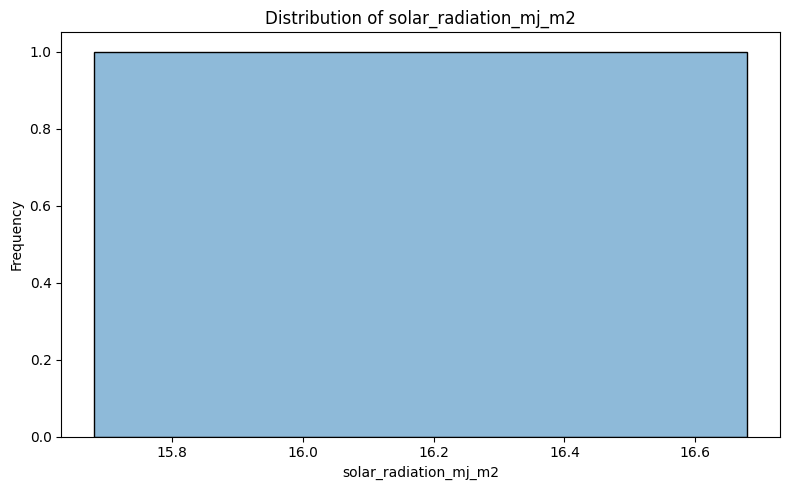

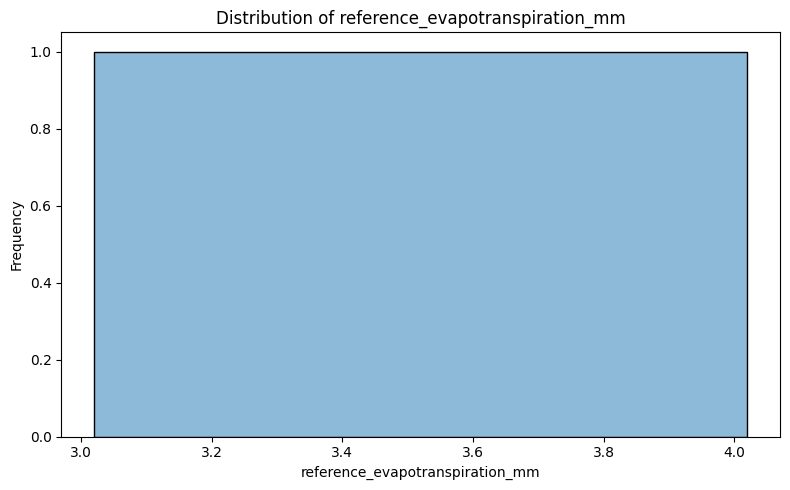

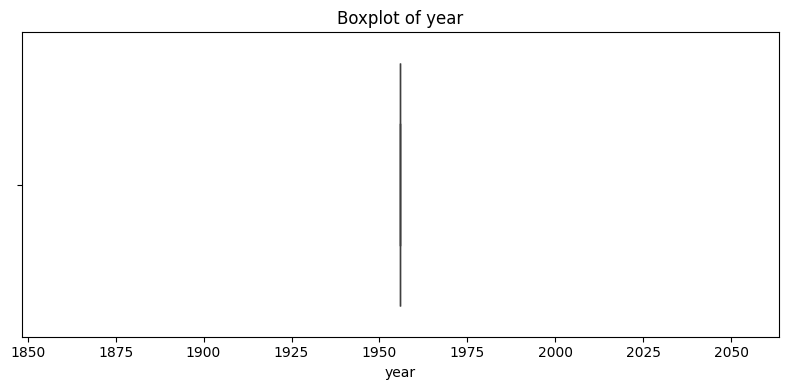

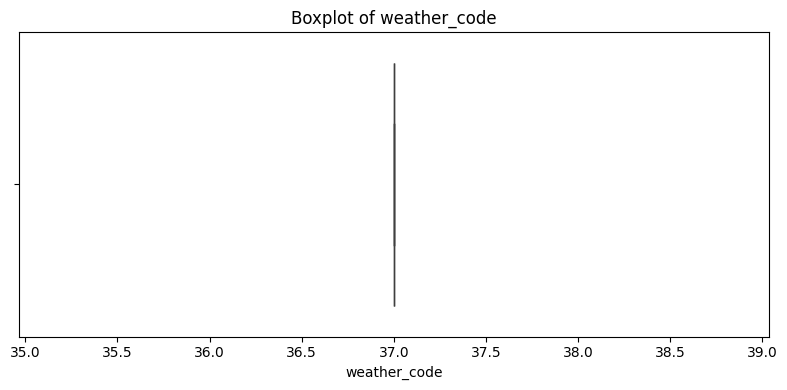

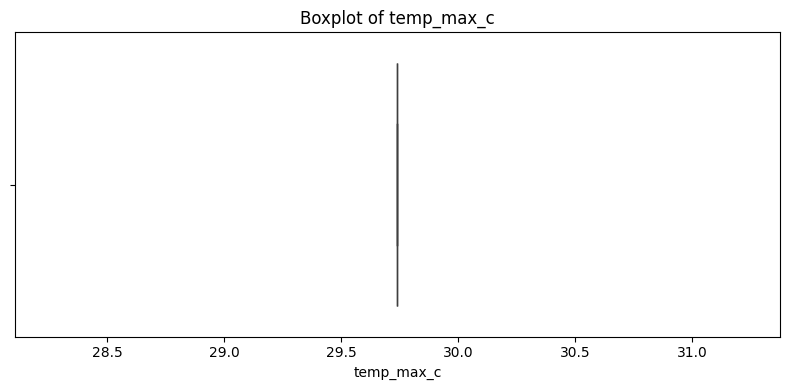

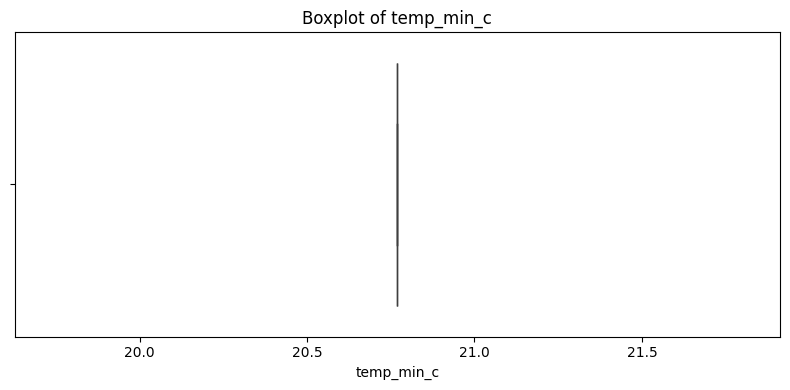

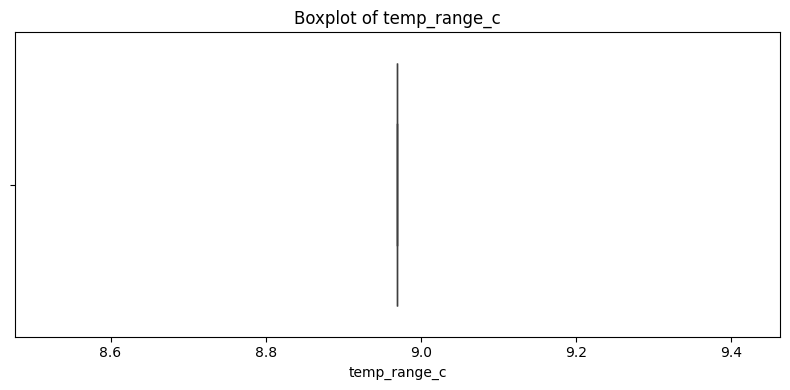

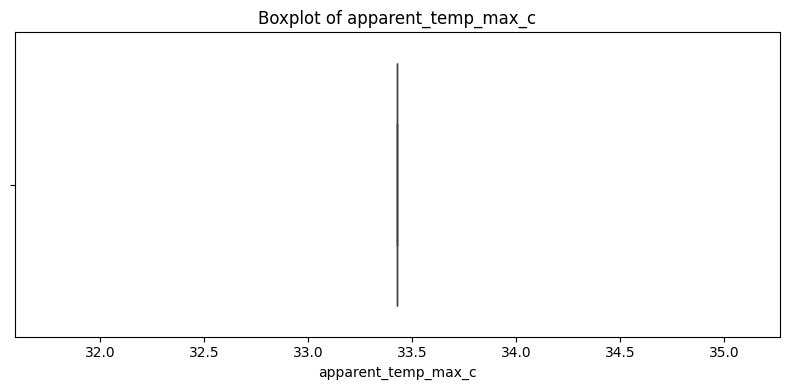

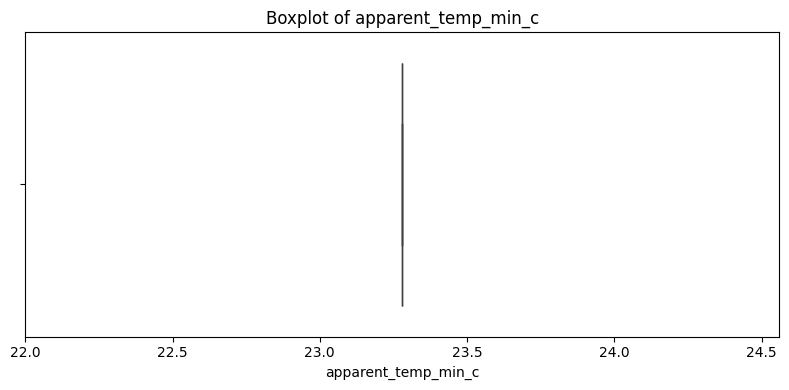

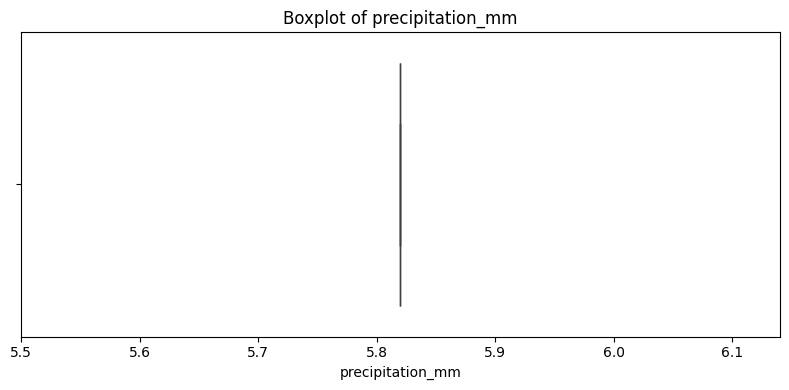

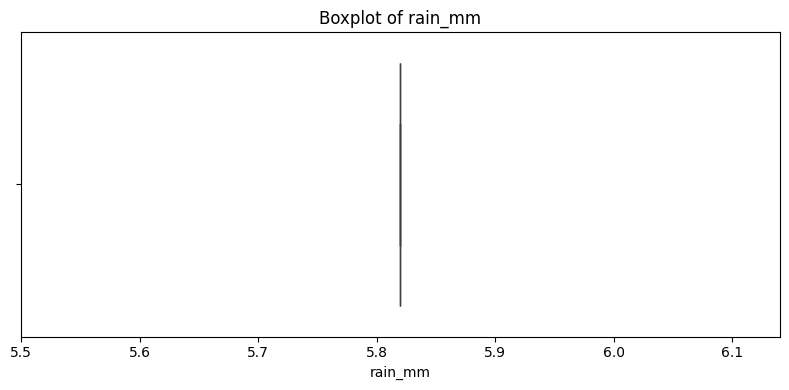

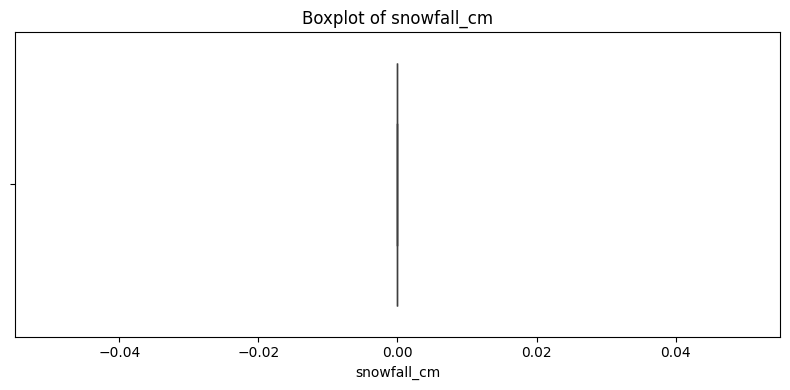

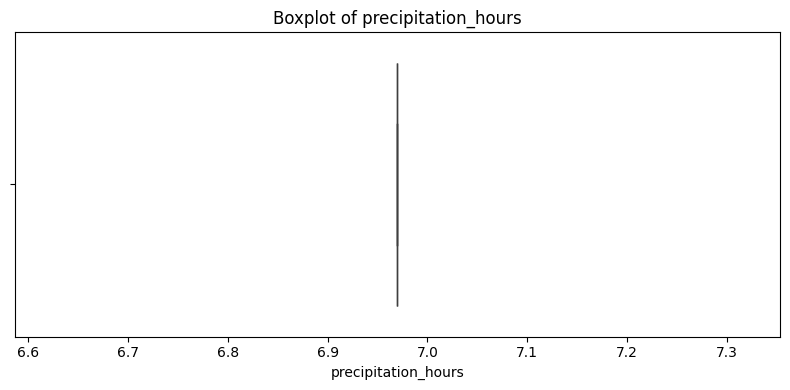

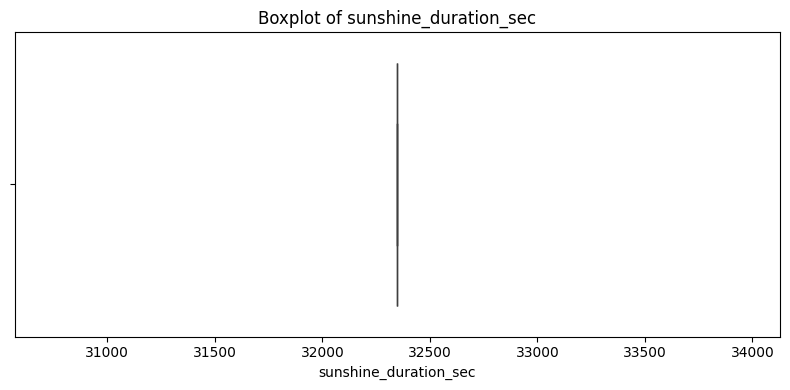

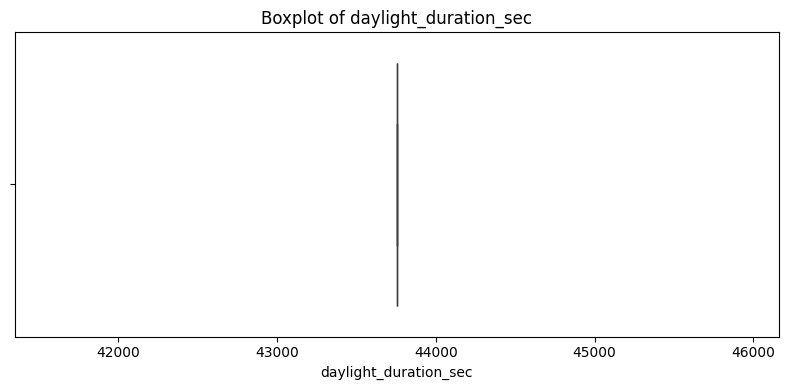

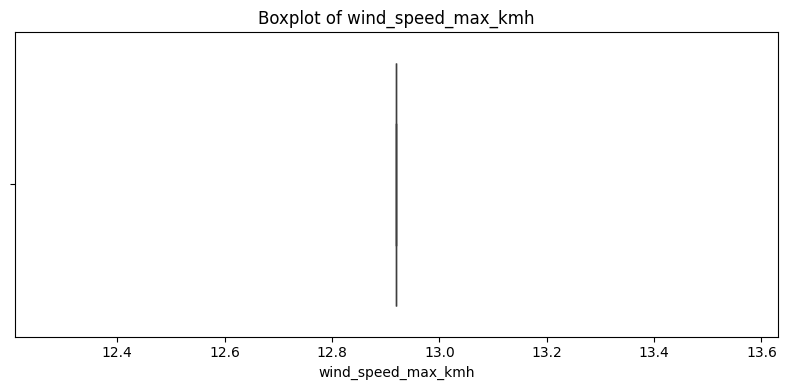

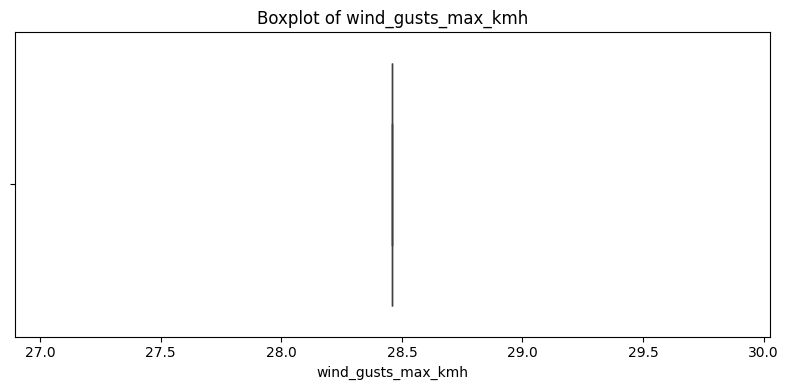

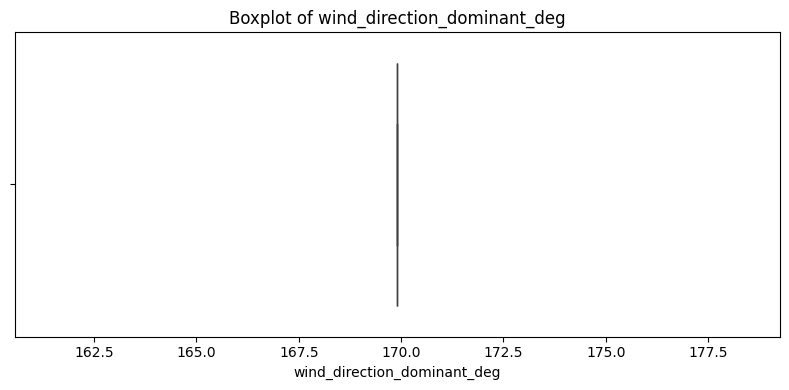

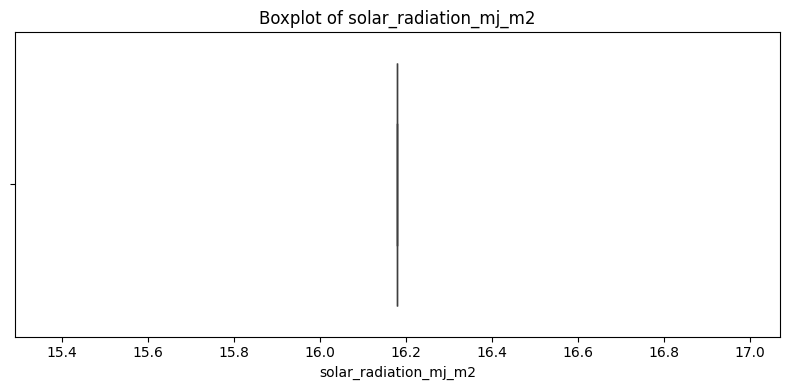

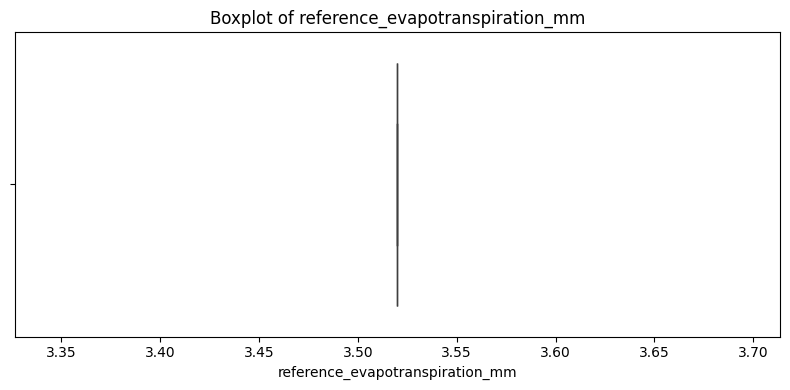


========== CORRELATION MATRIX ==========


,year,weather_code,temp_max_c,temp_min_c,temp_range_c,apparent_temp_max_c,apparent_temp_min_c,precipitation_mm,rain_mm,snowfall_cm,precipitation_hours,sunshine_duration_sec,daylight_duration_sec,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,solar_radiation_mj_m2,reference_evapotranspiration_mm
year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_code,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp_max_c,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp_min_c,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp_range_c,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
apparent_temp_max_c,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
apparent_temp_min_c,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
precipitation_mm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rain_mm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
snowfall_cm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


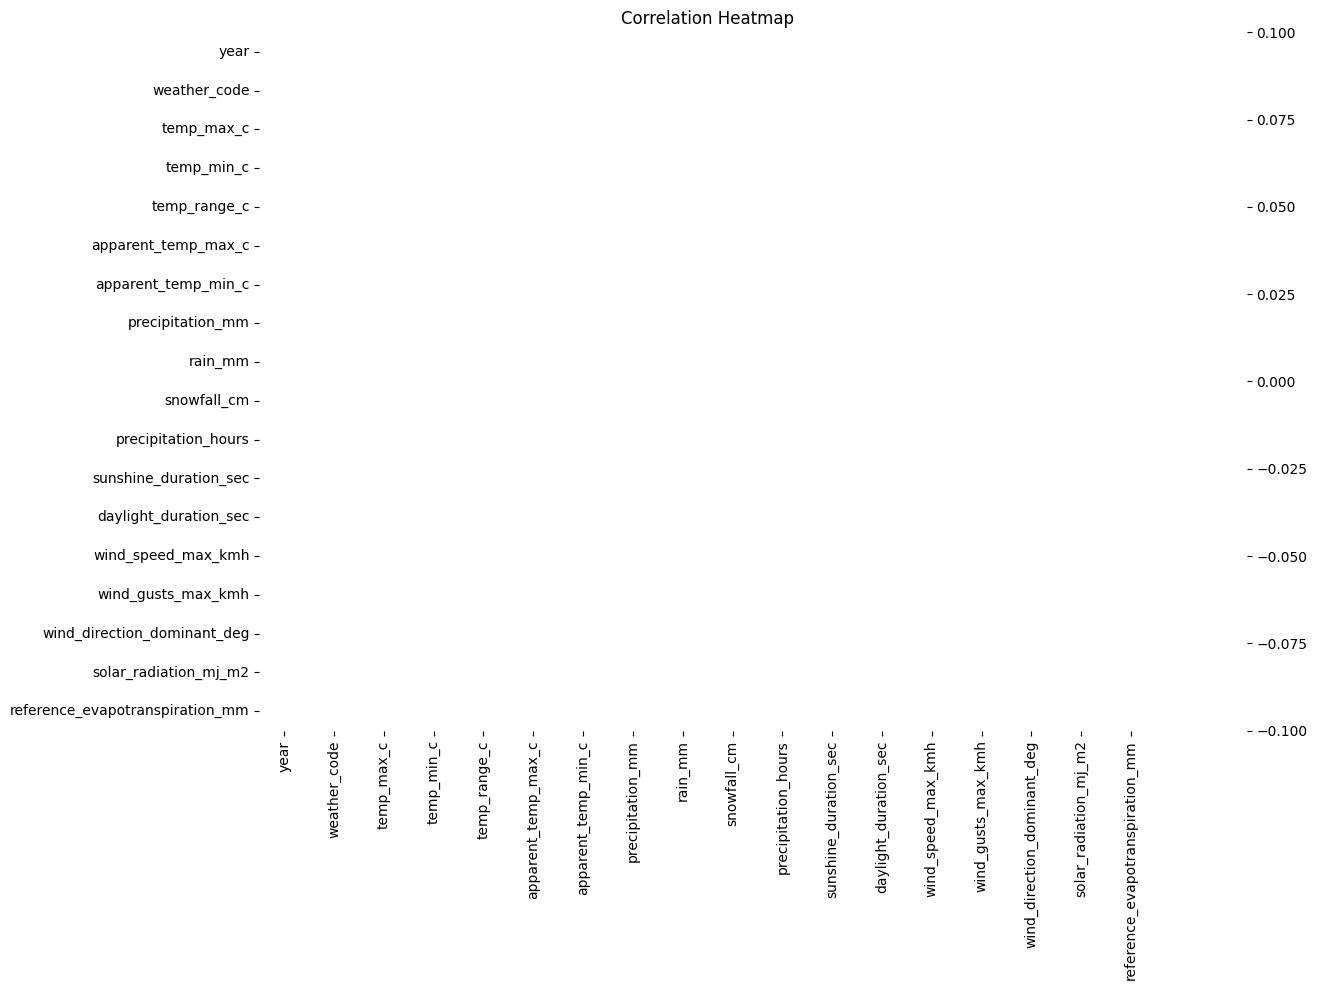

In [7]:

# ------------------------------------------------------------
# 3. LAST 5 ROWS
# ------------------------------------------------------------

print("\n========== LAST 5 ROWS ==========")
display(state_wise_df.tail())


# ------------------------------------------------------------
# 4. STATISTICAL SUMMARY
# ------------------------------------------------------------

print("\n========== STATISTICAL SUMMARY ==========")
display(state_wise_df.describe())


# ------------------------------------------------------------
# 5. NUMBER OF STATES
# ------------------------------------------------------------

print("\n========== NUMBER OF STATES ==========")
print("Total States:", state_wise_df["state"].nunique())


# ------------------------------------------------------------
# 6. STATE LIST
# ------------------------------------------------------------

print("\n========== STATES ==========")
print(state_wise_df["state"].tolist())


# ------------------------------------------------------------
# 7. MISSING VALUES
# ------------------------------------------------------------

print("\n========== MISSING VALUES ==========")

missing_values = state_wise_df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": (
        missing_values / len(state_wise_df) * 100
    ).round(2)
})

display(missing_table)


# ------------------------------------------------------------
# 8. DUPLICATE VALUES
# ------------------------------------------------------------

print("\n========== DUPLICATE ROWS ==========")
print(
    "Number of duplicate rows:",
    state_wise_df.duplicated().sum()
)


# ------------------------------------------------------------
# 9. DATA TYPES
# ------------------------------------------------------------

print("\n========== DATA TYPES ==========")
display(
    pd.DataFrame({
        "Column": state_wise_df.columns,
        "Data Type": state_wise_df.dtypes.astype(str)
    })
)


# ------------------------------------------------------------
# 10. UNIQUE VALUES
# ------------------------------------------------------------

print("\n========== UNIQUE VALUES ==========")

for column in state_wise_df.columns:
    print(
        f"{column}: {state_wise_df[column].nunique()} unique values"
    )


# ------------------------------------------------------------
# 11. NUMERIC COLUMNS
# ------------------------------------------------------------

numeric_columns = state_wise_df.select_dtypes(
    include=np.number
).columns.tolist()

print("\n========== NUMERIC COLUMNS ==========")
print(numeric_columns)


# ------------------------------------------------------------
# 12. DISTRIBUTION OF NUMERIC FEATURES
# ------------------------------------------------------------

for column in numeric_columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        state_wise_df[column],
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 13. BOXPLOTS FOR OUTLIER DETECTION
# ------------------------------------------------------------

for column in numeric_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=state_wise_df[column]
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 14. CORRELATION MATRIX
# ------------------------------------------------------------

print("\n========== CORRELATION MATRIX ==========")

correlation_matrix = state_wise_df[
    numeric_columns
].corr()

display(correlation_matrix)


# ------------------------------------------------------------
# 15. CORRELATION HEATMAP
# ------------------------------------------------------------

plt.figure(
    figsize=(14, 10)
)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 16. TEMPERATURE COMPARISON BY STATE
# ------------------------------------------------------------

if "temp_max" in state_wise_df.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=state_wise_df,
        x="state",
        y="temp_max"
    )

    plt.title("Average Maximum Temperature by State")
    plt.xlabel("State")
    plt.ylabel("Temperature")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 17. MINIMUM TEMPERATURE BY STATE
# ------------------------------------------------------------

if "temp_min" in state_wise_df.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=state_wise_df,
        x="state",
        y="temp_min"
    )

    plt.title("Average Minimum Temperature by State")
    plt.xlabel("State")
    plt.ylabel("Temperature")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


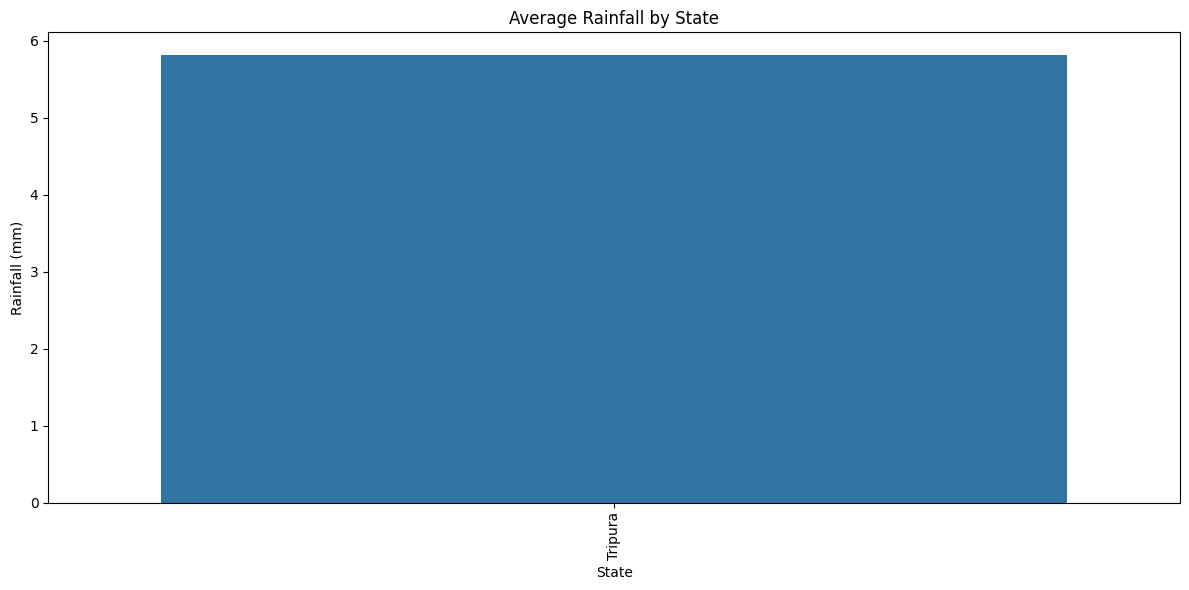


EDA COMPLETED SUCCESSFULLY
Number of states: 1
Number of features: 19
Missing values: 0
Duplicate rows: 0


In [8]:


# ------------------------------------------------------------
# 18. RAINFALL BY STATE
# ------------------------------------------------------------

if "rain_mm" in state_wise_df.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=state_wise_df,
        x="state",
        y="rain_mm"
    )

    plt.title("Average Rainfall by State")
    plt.xlabel("State")
    plt.ylabel("Rainfall (mm)")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 19. SUNSHINE DURATION BY STATE
# ------------------------------------------------------------

if "sunshine_duration" in state_wise_df.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=state_wise_df,
        x="state",
        y="sunshine_duration"
    )

    plt.title("Average Sunshine Duration by State")
    plt.xlabel("State")
    plt.ylabel("Sunshine Duration")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 20. FINAL EDA SUMMARY
# ------------------------------------------------------------

print("\n========================================")
print("EDA COMPLETED SUCCESSFULLY")
print("========================================")

print("Number of states:",
      state_wise_df["state"].nunique())

print("Number of features:",
      len(state_wise_df.columns))

print("Missing values:",
      state_wise_df.isnull().sum().sum())

print("Duplicate rows:",
      state_wise_df.duplicated().sum())

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd

# Keep the year as an actual year, not an average of daily years.
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["state", "year"]).copy()
df["year"] = df["year"].astype(int)

# Columns representing totals over daily observations.
sum_columns = [
    "precipitation_mm",
    "rain_mm",
    "snowfall_cm",
    "precipitation_hours",
    "sunshine_duration_sec",
    "reference_evapotranspiration_mm",
]

# Aggregate numeric weather features within each state and year.
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

mean_columns = [
    col for col in numeric_columns
    if col not in sum_columns and col != "year"
]

aggregation = {
    col: "mean" for col in mean_columns
}
aggregation.update({
    col: "sum" for col in sum_columns
    if col in df.columns
})

weather_yearly = (
    df.groupby(["state", "year"], as_index=False)
      .agg(aggregation)
)

weather_yearly = weather_yearly.rename(columns={
    "state": "State",
    "year": "Year"
})

output_dir = Path("../data/processed_data")
output_dir.mkdir(parents=True, exist_ok=True)

weather_yearly.to_csv(
    output_dir / "weather_state_year_preprocessed.csv",
    index=False
)

print("Saved yearly state-level weather data.")
print(weather_yearly.shape)
print(weather_yearly.head())

Saved yearly state-level weather data.
(33, 19)
     State  Year  weather_code  temp_max_c  temp_min_c  temp_range_c  \
0  Tripura  1940     40.939891   29.200546   20.533607      8.666940   
1  Tripura  1941     39.095890   29.664384   20.295342      9.369041   
2  Tripura  1942     35.263014   30.151233   20.556164      9.595068   
3  Tripura  1943     37.054795   29.765479   20.630959      9.134521   
4  Tripura  1944     33.448087   30.598361   20.863934      9.734426   

   apparent_temp_max_c  apparent_temp_min_c  daylight_duration_sec  \
0            33.258743            23.206831           43733.032022   
1            33.237808            22.707671           43747.130493   
2            33.302740            22.901370           43747.195726   
3            33.312603            23.174247           43747.439014   
4            33.646448            22.923770           43733.029945   

   wind_speed_max_kmh  wind_gusts_max_kmh  wind_direction_dominant_deg  \
0           12.019672   